# Análise exploratória do PTB-XL v1.0.3

**DCA3606 — Inteligência Artificial (UFRN).** Objetivos futuros: classificação binária *Normal × Alterado* e regressão da idade cronológica a partir de ECGs. Este notebook apenas inspeciona os dados; não ajusta transformações nem treina modelos.

Os arquivos originais são lidos por caminhos relativos. Os gráficos são salvos em `resultados/eda/`. Para executar: `pip install numpy pandas matplotlib wfdb ipykernel`. Execute a partir da raiz do projeto, ou deixe que a busca relativa abaixo encontre o diretório do dataset.

In [1]:
from pathlib import Path
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from IPython.display import display

SEMENTE = 3606
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

raiz_projeto = Path.cwd()
candidatos = [raiz_projeto] + list(raiz_projeto.glob('ptb-xl-1.0.3/*'))
raiz_dados = next((p for p in candidatos if (p / 'ptbxl_database.csv').is_file()
                   and (p / 'scp_statements.csv').is_file()
                   and (p / 'records100').is_dir()), None)
if raiz_dados is None:
    raise FileNotFoundError('Não encontrei ptbxl_database.csv, scp_statements.csv e records100/ a partir do diretório atual.')
pasta_figuras = raiz_projeto / 'resultados' / 'eda'
pasta_figuras.mkdir(parents=True, exist_ok=True)
print('Dataset:', raiz_dados.relative_to(raiz_projeto))
print('Figuras:', pasta_figuras.relative_to(raiz_projeto))
print('Versões:', {'pandas': pd.__version__, 'numpy': np.__version__, 'matplotlib': plt.matplotlib.__version__, 'wfdb': wfdb.__version__})

Dataset: ptb-xl-1.0.3/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Figuras: resultados/eda
Versões: {'pandas': '3.1.1', 'numpy': '2.5.5', 'matplotlib': '3.11.2', 'wfdb': '4.3.1'}


## 1. Estrutura e qualidade dos metadados

Uma linha da tabela principal representa um ECG. `ecg_id` identifica o exame e `patient_id` o paciente; múltiplos exames do mesmo paciente não são duplicatas por si. `filename_lr` aponta ao sinal de 100 Hz. Os nomes e tipos de todas as colunas são mostrados abaixo; a tabela de significados organiza as variáveis relevantes para as duas tarefas.

21,799 ECGs; 18,869 pacientes; 28 colunas; 71 códigos SCP catalogados.


,coluna,tipo,ausentes,significado
0,ecg_id,int64,0,Identificador do exame
1,patient_id,float64,0,Identificador do paciente
2,age,float64,0,"Idade registrada; 300 representa anonimização,..."
3,sex,int64,0,Sexo codificado no dataset
4,height,float64,14825,Altura
5,weight,float64,12378,Peso
6,nurse,float64,1473,Identificador do profissional
7,site,float64,17,Local de aquisição
8,device,str,0,Equipamento
9,recording_date,str,0,Data/hora da gravação


Registros por paciente:


,count,mean,std,min,25%,50%,75%,max
ECGs por paciente,18869.0,1.155281,0.523105,1.0,1.0,1.0,1.0,10.0


Maiores quantidades de registros por paciente:


,ECGs
patient_id,
9898.0,10
17542.0,9
10107.0,9
8304.0,9
15765.0,8
13145.0,8
13619.0,8
8810.0,8
20655.0,7


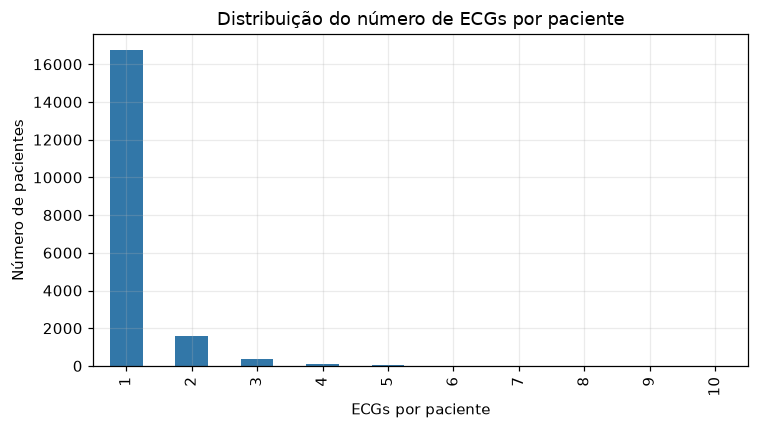

In [2]:
df = pd.read_csv(raiz_dados / 'ptbxl_database.csv')
scp = pd.read_csv(raiz_dados / 'scp_statements.csv', index_col=0)
print(f'{len(df):,} ECGs; {df.patient_id.nunique(dropna=True):,} pacientes; {df.shape[1]} colunas; {len(scp)} códigos SCP catalogados.')
significados = {
    'ecg_id': 'Identificador do exame', 'patient_id': 'Identificador do paciente',
    'age': 'Idade registrada; 300 representa anonimização, não idade real',
    'sex': 'Sexo codificado no dataset', 'height': 'Altura', 'weight': 'Peso',
    'nurse': 'Identificador do profissional', 'site': 'Local de aquisição',
    'device': 'Equipamento', 'recording_date': 'Data/hora da gravação',
    'report': 'Laudo textual', 'scp_codes': 'Dicionário de códigos SCP e pesos da anotação',
    'heart_axis': 'Eixo cardíaco anotado',
    'infarction_stadium1': 'Estágio de infarto anotado (1)',
    'infarction_stadium2': 'Estágio de infarto anotado (2)',
    'validated_by': 'Identificador de validação',
    'second_opinion': 'Indicador de segunda opinião',
    'initial_autogenerated_report': 'Indicador de laudo inicial automático',
    'validated_by_human': 'Indicador de validação humana',
    'baseline_drift': 'Anotação de deriva de linha de base',
    'static_noise': 'Anotação de ruído estático',
    'burst_noise': 'Anotação de ruído em rajadas',
    'electrodes_problems': 'Anotação de problemas nos eletrodos',
    'extra_beats': 'Anotação de batimentos extras',
    'pacemaker': 'Anotação de marcapasso',
    'strat_fold': 'Fold oficial estratificado (1–10)',
    'filename_lr': 'Caminho relativo do sinal de 100 Hz',
    'filename_hr': 'Caminho relativo do sinal de 500 Hz'
}
estrutura = pd.DataFrame({'coluna': df.columns, 'tipo': df.dtypes.astype(str).values,
                           'ausentes': df.isna().sum().values,
                           'significado': [significados.get(c, 'Consultar documentação do dataset') for c in df.columns]})
display(estrutura)
assert set(df.columns) == set(significados), 'Revisar significados: o esquema do CSV mudou.'
print('Registros por paciente:')
display(df.groupby('patient_id', dropna=False).size().describe().to_frame('ECGs por paciente').T)
print('Maiores quantidades de registros por paciente:')
display(df.groupby('patient_id', dropna=False).size().sort_values(ascending=False).head(10).to_frame('ECGs'))
fig, ax = plt.subplots(figsize=(7, 4))
df.groupby('patient_id', dropna=False).size().value_counts().sort_index().plot.bar(ax=ax, color='#3277a8')
ax.set(title='Distribuição do número de ECGs por paciente', xlabel='ECGs por paciente', ylabel='Número de pacientes')
fig.tight_layout(); fig.savefig(pasta_figuras / 'registros_por_paciente.png'); plt.show()

,ausentes
patient_id,0
age,0
scp_codes,0
strat_fold,0
filename_lr,0


,verificação,quantidade
0,ecg_id repetido,0
1,filename_lr repetido,0
2,linhas integralmente iguais,0
3,metadados iguais sem IDs e caminhos,2


IDs dos candidatos com metadados iguais:


,ecg_id,patient_id,recording_date,filename_lr
11810,11842,13781.0,1994-02-26 11:09:57,records100/11000/11842_lr
11811,11843,13781.0,1994-02-26 11:09:57,records100/11000/11843_lr


A última linha indica apenas candidatos a inspeção; metadados iguais não provam sinais duplicados.


,exames,pacientes
strat_fold,,
1,2175,1878
2,2181,1849
3,2192,1887
4,2174,1883
5,2174,1890
6,2173,1884
7,2176,1871
8,2173,1881
9,2183,1942


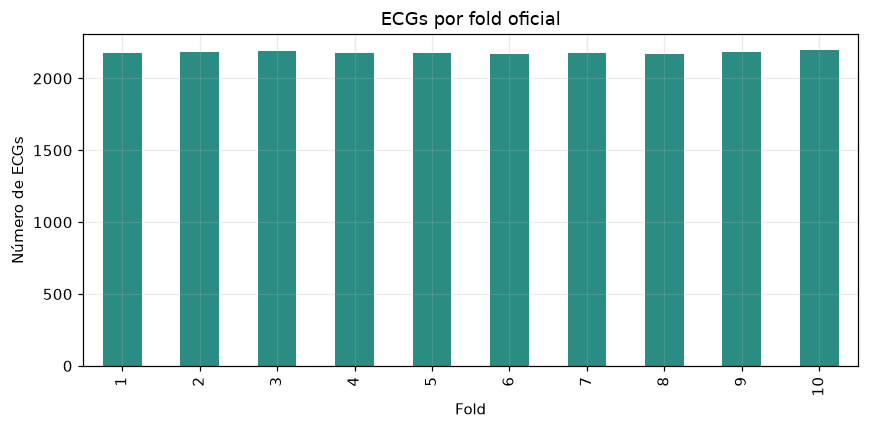

In [3]:
variaveis_chave = ['patient_id', 'age', 'scp_codes', 'strat_fold', 'filename_lr']
display(df[variaveis_chave].isna().sum().rename('ausentes').to_frame())
checagem_duplicatas = pd.DataFrame({'verificação': ['ecg_id repetido', 'filename_lr repetido', 'linhas integralmente iguais',
                                                       'metadados iguais sem IDs e caminhos'],
    'quantidade': [df.duplicated('ecg_id', keep=False).sum(),
                   df.duplicated('filename_lr', keep=False).sum(),
                   df.duplicated(keep=False).sum(),
                   df.drop(columns=['ecg_id', 'filename_lr', 'filename_hr']).duplicated(keep=False).sum()]})
display(checagem_duplicatas)
candidatos_meta = df.loc[df.drop(columns=['ecg_id', 'filename_lr', 'filename_hr']).duplicated(keep=False),
                         ['ecg_id', 'patient_id', 'recording_date', 'filename_lr']]
print('IDs dos candidatos com metadados iguais:')
display(candidatos_meta)
print('A última linha indica apenas candidatos a inspeção; metadados iguais não provam sinais duplicados.')
folds = df.groupby('strat_fold', dropna=False).agg(exames=('ecg_id', 'size'), pacientes=('patient_id', 'nunique'))
display(folds)
fig, ax = plt.subplots(figsize=(8, 4))
folds['exames'].plot.bar(ax=ax, color='#2b8c83')
ax.set(title='ECGs por fold oficial', xlabel='Fold', ylabel='Número de ECGs')
fig.tight_layout(); fig.savefig(pasta_figuras / 'exames_por_fold.png'); plt.show()

## 2. Diagnósticos SCP e viabilidade da classificação

`scp_codes` é convertido com `ast.literal_eval`, sem executar código arbitrário. Apenas códigos cujo campo `diagnostic` vale 1 em `scp_statements.csv` entram no agrupamento. A presença da chave diagnóstica é usada como anotação, sem transformar seus pesos em probabilidade ou impor limiar não documentado. Um exame pode pertencer a várias superclasses; as frequências relativas abaixo têm como denominador **todos os ECGs** e podem somar mais de 100%.

Códigos observados sem entrada no catálogo SCP: []
Códigos diagnósticos sem uma das cinco superclasses: []


,superclasse,exames,frequência_relativa_%
0,NORM,9514,43.644204
1,MI,5469,25.088307
2,STTC,5235,24.014863
3,CD,4898,22.468921
4,HYP,2649,12.151934


ECGs com múltiplas superclasses: 5144
ECGs com múltiplos códigos diagnósticos: 6392
ECGs sem superclasse diagnóstica: 411


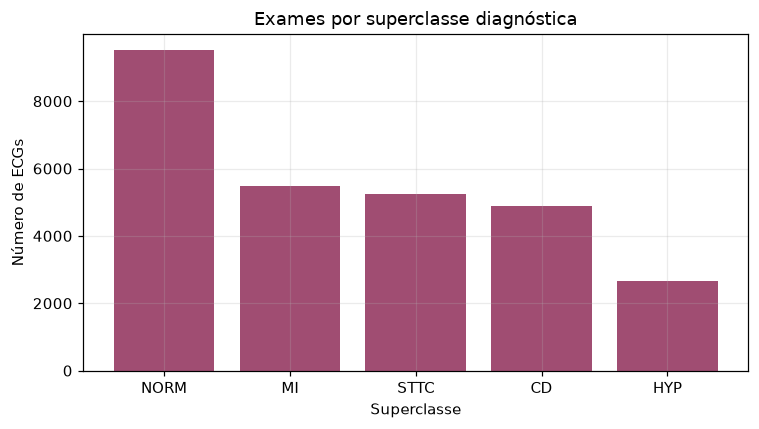

,NORM,MI,STTC,CD,HYP
strat_fold,,,,,
1,940,549,526,481,263
2,967,538,524,485,264
3,991,528,515,487,264
4,927,551,527,494,261
5,939,563,532,496,265
6,930,562,528,494,270
7,970,550,520,478,264
8,932,538,514,492,268
9,955,540,528,495,268


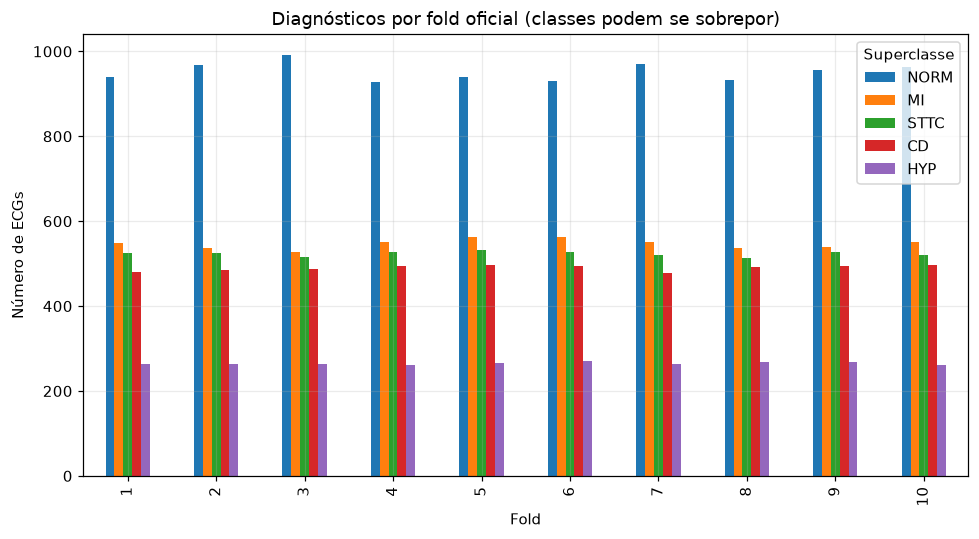

In [4]:
def ler_codigos(valor):
    if pd.isna(valor): return {}
    try:
        convertido = ast.literal_eval(valor)
        return convertido if isinstance(convertido, dict) else {}
    except (ValueError, SyntaxError, TypeError):
        return {}

df['codigos_scp'] = df.scp_codes.map(ler_codigos)
codigos_diagnosticos = scp.loc[pd.to_numeric(scp['diagnostic'], errors='coerce').eq(1)]
classes = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
mapa_superclasses = codigos_diagnosticos['diagnostic_class'].to_dict()
codigos_observados = set().union(*(d.keys() for d in df.codigos_scp))
sem_catalogo = codigos_observados - set(scp.index)
print('Códigos observados sem entrada no catálogo SCP:', sorted(sem_catalogo))
print('Códigos diagnósticos sem uma das cinco superclasses:',
      codigos_diagnosticos.loc[~codigos_diagnosticos.diagnostic_class.isin(classes)].index.tolist())
df['superclasses'] = df.codigos_scp.map(lambda d: set(mapa_superclasses[c] for c in d
                                                      if c in mapa_superclasses and mapa_superclasses[c] in classes))
for classe in classes:
    df[classe] = df.superclasses.map(lambda s: classe in s)
resumo_classes = pd.DataFrame({'superclasse': classes,
    'exames': [int(df[c].sum()) for c in classes],
    'frequência_relativa_%': [100 * df[c].mean() for c in classes]})
display(resumo_classes)
quantidade_classes = df.superclasses.map(len)
print('ECGs com múltiplas superclasses:', int(quantidade_classes.gt(1).sum()))
print('ECGs com múltiplos códigos diagnósticos:', int(df.codigos_scp.map(lambda d: sum(c in mapa_superclasses for c in d)).gt(1).sum()))
print('ECGs sem superclasse diagnóstica:', int(quantidade_classes.eq(0).sum()))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(resumo_classes.superclasse, resumo_classes.exames, color='#a04d72')
ax.set(title='Exames por superclasse diagnóstica', xlabel='Superclasse', ylabel='Número de ECGs')
fig.tight_layout(); fig.savefig(pasta_figuras / 'superclasses.png'); plt.show()
por_fold = df.groupby('strat_fold')[classes].sum().astype(int)
display(por_fold)
fig, ax = plt.subplots(figsize=(9, 5))
por_fold.plot.bar(ax=ax)
ax.set(title='Diagnósticos por fold oficial (classes podem se sobrepor)', xlabel='Fold', ylabel='Número de ECGs')
ax.legend(title='Superclasse')
fig.tight_layout(); fig.savefig(pasta_figuras / 'diagnosticos_por_fold.png'); plt.show()

### Regra proposta para o alvo binário

- **Normal:** há `NORM` e nenhuma das quatro superclasses de alteração.
- **Alterado:** há ao menos uma entre `MI`, `STTC`, `CD`, `HYP` e não há `NORM`.
- **Exclusão provisória:** `NORM` junto de alteração (ambíguo) ou nenhuma superclasse diagnóstica reconhecida (informação insuficiente).

Os critérios usam somente as cinco superclasses diagnósticas do catálogo. O alvo é apenas uma proposta para a etapa futura; nenhuma linha é removida neste notebook. A disponibilidade do sinal será contada separadamente.

In [5]:
tem_alteracao = df[['MI', 'STTC', 'CD', 'HYP']].any(axis=1)
condicoes = [df.NORM & ~tem_alteracao, ~df.NORM & tem_alteracao,
             df.NORM & tem_alteracao]
escolhas = ['Normal', 'Alterado', 'Excluído: NORM e alteração']
df['grupo_binario'] = np.select(condicoes, escolhas, default='Excluído: sem diagnóstico suficiente')
resumo_regra = df.grupo_binario.value_counts().rename_axis('situação').to_frame('ECGs')
display(resumo_regra)
print('Aproveitáveis pelo diagnóstico:', int(df.grupo_binario.isin(['Normal', 'Alterado']).sum()))
print('Excluídos pelo diagnóstico:', int((~df.grupo_binario.isin(['Normal', 'Alterado'])).sum()))
print('Códigos não diagnósticos ou desconhecidos não definem o alvo binário.')

,ECGs
situação,
Alterado,11874
Normal,9069
Excluído: NORM e alteração,445
Excluído: sem diagnóstico suficiente,411


Aproveitáveis pelo diagnóstico: 20943
Excluídos pelo diagnóstico: 856
Códigos não diagnósticos ou desconhecidos não definem o alvo binário.


## 3. Idade e viabilidade da regressão

O valor **300** representa anonimização de idade elevada e não deve ser usado como idade cronológica. O critério provisório é idade numérica, finita, maior que zero e menor que 300. Essa regra não substitui uma futura análise de sensibilidade da distribuição etária. Gráficos e estatísticas descritivas usam somente idades cronológicas elegíveis.

,situação,ECGs
0,Idade válida,21506
1,Ausente/não numérica,0
2,Valor 300 (anonimizado),293
3,Outros valores inválidos,0


,anos
min,2.000000
max,89.000000
mean,59.537245
median,61.000000
std,16.758773


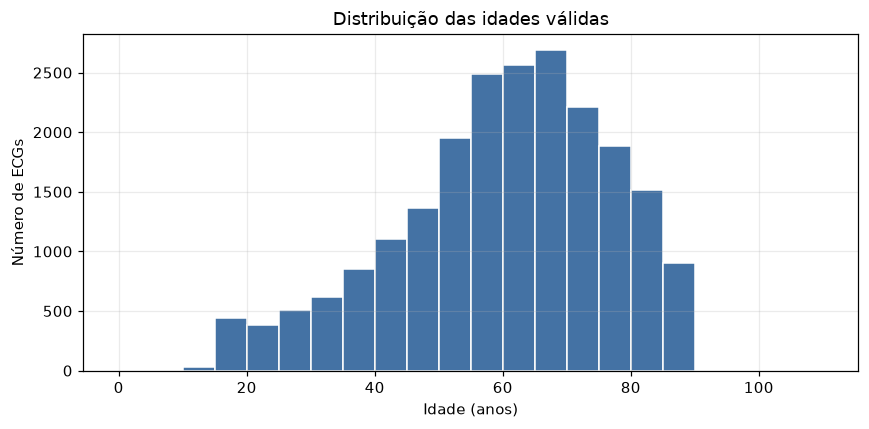

/tmp/ipykernel_57186/1376418310.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(idade[idade_valida], vert=False)


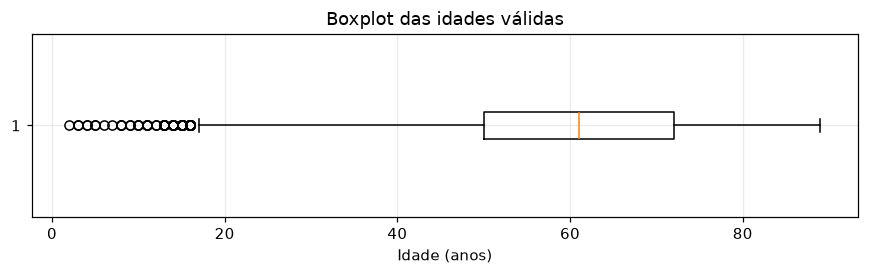

,count,min,median,mean,max,std
strat_fold,,,,,,
1,2151,6.0,61.0,59.341702,89.0,16.537257
2,2151,7.0,61.0,59.078568,89.0,16.657504
3,2159,3.0,61.0,59.208893,89.0,16.711347
4,2149,9.0,61.0,59.705444,89.0,16.700095
5,2150,9.0,61.0,59.361860,89.0,16.419360
6,2147,5.0,61.0,59.334886,89.0,16.694255
7,2149,5.0,61.0,59.473709,89.0,16.673077
8,2145,2.0,61.0,59.307692,89.0,16.692552
9,2141,3.0,62.0,59.878561,89.0,17.138011


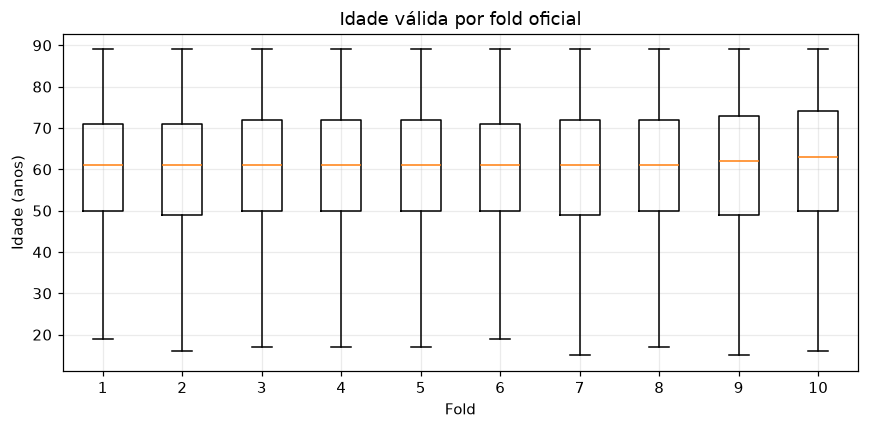

,count,mean,median,std
grupo_binario,,,,
Alterado,11620,65.401291,67.0,13.771392
Normal,9039,51.996570,53.0,17.200859


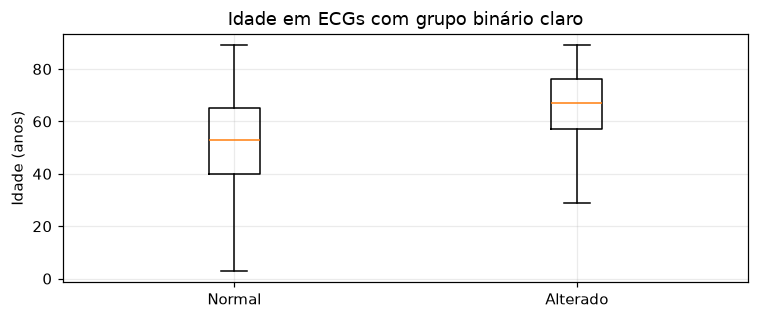

In [6]:
df['idade_numerica'] = pd.to_numeric(df.age, errors='coerce')
idade = df.idade_numerica
idade_valida = idade.notna() & np.isfinite(idade) & idade.gt(0) & idade.lt(300)
df['idade_valida'] = idade_valida
resumo_idade = pd.DataFrame({'situação': ['Idade válida', 'Ausente/não numérica', 'Valor 300 (anonimizado)',
                                           'Outros valores inválidos'],
    'ECGs': [int(idade_valida.sum()), int(idade.isna().sum()), int(idade.eq(300).sum()),
             int((idade.notna() & ~idade_valida & ~idade.eq(300)).sum())]})
display(resumo_idade)
display(idade[idade_valida].agg(['min', 'max', 'mean', 'median', 'std']).rename('anos').to_frame())
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(idade[idade_valida], bins=range(0, 111, 5), color='#4472a4', edgecolor='white')
ax.set(title='Distribuição das idades válidas', xlabel='Idade (anos)', ylabel='Número de ECGs')
fig.tight_layout(); fig.savefig(pasta_figuras / 'histograma_idades.png'); plt.show()
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.boxplot(idade[idade_valida], vert=False)
ax.set(title='Boxplot das idades válidas', xlabel='Idade (anos)')
fig.tight_layout(); fig.savefig(pasta_figuras / 'boxplot_idades.png'); plt.show()
idade_fold = df.loc[idade_valida].groupby('strat_fold').idade_numerica.agg(['count', 'min', 'median', 'mean', 'max', 'std'])
display(idade_fold)
fig, ax = plt.subplots(figsize=(8, 4))
dados_fold = [df.loc[idade_valida & df.strat_fold.eq(f), 'idade_numerica'].values for f in range(1, 11)]
ax.boxplot(dados_fold, tick_labels=list(range(1, 11)), showfliers=False)
ax.set(title='Idade válida por fold oficial', xlabel='Fold', ylabel='Idade (anos)')
fig.tight_layout(); fig.savefig(pasta_figuras / 'idades_por_fold.png'); plt.show()
grupos_claros = df.loc[idade_valida & df.grupo_binario.isin(['Normal', 'Alterado'])]
display(grupos_claros.groupby('grupo_binario').idade_numerica.agg(['count', 'mean', 'median', 'std']))
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([grupos_claros.loc[grupos_claros.grupo_binario.eq(g), 'idade_numerica'] for g in ['Normal', 'Alterado']],
           tick_labels=['Normal', 'Alterado'], showfliers=False)
ax.set(title='Idade em ECGs com grupo binário claro', ylabel='Idade (anos)')
fig.tight_layout(); fig.savefig(pasta_figuras / 'idades_por_grupo.png'); plt.show()

## 4. Disponibilidade e inspeção amostral dos sinais

A verificação de disponibilidade testa os caminhos `.hea` e `.dat` indicados por `filename_lr`, sem ler os sinais. A inspeção WFDB abaixo lê apenas alguns registros selecionados com semente fixa. As unidades físicas vêm dos cabeçalhos WFDB; a comparação usa a mesma derivação e escala vertical comum. Os diagnósticos exibidos são anotações do dataset, sem interpretação clínica adicional.

In [7]:
def arquivos_presentes(nome):
    if not isinstance(nome, str) or not nome.startswith('records100/'):
        return False
    base = raiz_dados / nome
    return base.with_suffix('.hea').is_file() and base.with_suffix('.dat').is_file()

df['sinal_disponivel'] = df.filename_lr.map(arquivos_presentes)
print('Pares .hea/.dat disponíveis:', int(df.sinal_disponivel.sum()), '/', len(df))
print('Caminhos ausentes ou incompletos:', int((~df.sinal_disponivel).sum()))

amostras = []
for grupo in ['Normal', 'Alterado']:
    disponiveis = df.loc[df.sinal_disponivel & df.grupo_binario.eq(grupo)]
    amostras.append(disponiveis.sample(n=min(2, len(disponiveis)), random_state=SEMENTE))
amostra = pd.concat(amostras)
if len(amostra) < 2:
    raise ValueError('Não há exemplos suficientes dos dois grupos para a inspeção visual.')

sinais = {}
inspecao = []
for _, linha in amostra.iterrows():
    registro = wfdb.rdrecord(str(raiz_dados / linha.filename_lr))
    sinal = registro.p_signal
    ecg_id = int(linha.ecg_id)
    sinais[ecg_id] = registro
    finitos = np.isfinite(sinal)
    inspecao.append({'ecg_id': ecg_id, 'grupo': linha.grupo_binario,
        'anotações SCP': ', '.join(linha.codigos_scp.keys()),
        'amostras × derivações': str(sinal.shape), 'derivações': registro.n_sig,
        'frequência (Hz)': registro.fs, 'duração (s)': len(sinal) / registro.fs,
        'NaN': int(np.isnan(sinal).sum()), 'infinitos': int(np.isinf(sinal).sum()),
        'mínimo': float(np.nanmin(sinal)), 'máximo': float(np.nanmax(sinal)),
        'derivações constantes': ', '.join(np.array(registro.sig_name)[np.ptp(sinal, axis=0) < 1e-12]),
        'unidades': ', '.join(sorted(set(registro.units)))})
display(pd.DataFrame(inspecao))
print('Sinais com valores não finitos:', sum(x['NaN'] + x['infinitos'] > 0 for x in inspecao))
print('Observação: ausência de defeito evidente nesta amostra não certifica todos os arquivos.')

Pares .hea/.dat disponíveis: 21799 / 21799
Caminhos ausentes ou incompletos: 0


,ecg_id,grupo,anotações SCP,amostras × derivações,derivações,frequência (Hz),duração (s),NaN,infinitos,mínimo,máximo,derivações constantes,unidades
0,16021,Normal,"NORM, STACH","(1000, 12)",12,100,10.0,0,0,-0.958,1.526,,mV
1,13568,Normal,"NORM, SR","(1000, 12)",12,100,10.0,0,0,-1.229,1.955,,mV
2,5147,Alterado,"ALMI, ABQRS, SR","(1000, 12)",12,100,10.0,0,0,-1.428,0.783,,mV
3,17552,Alterado,"LVH, ISC_, PVC, AFIB","(1000, 12)",12,100,10.0,0,0,-0.992,2.197,,mV


Sinais com valores não finitos: 0
Observação: ausência de defeito evidente nesta amostra não certifica todos os arquivos.


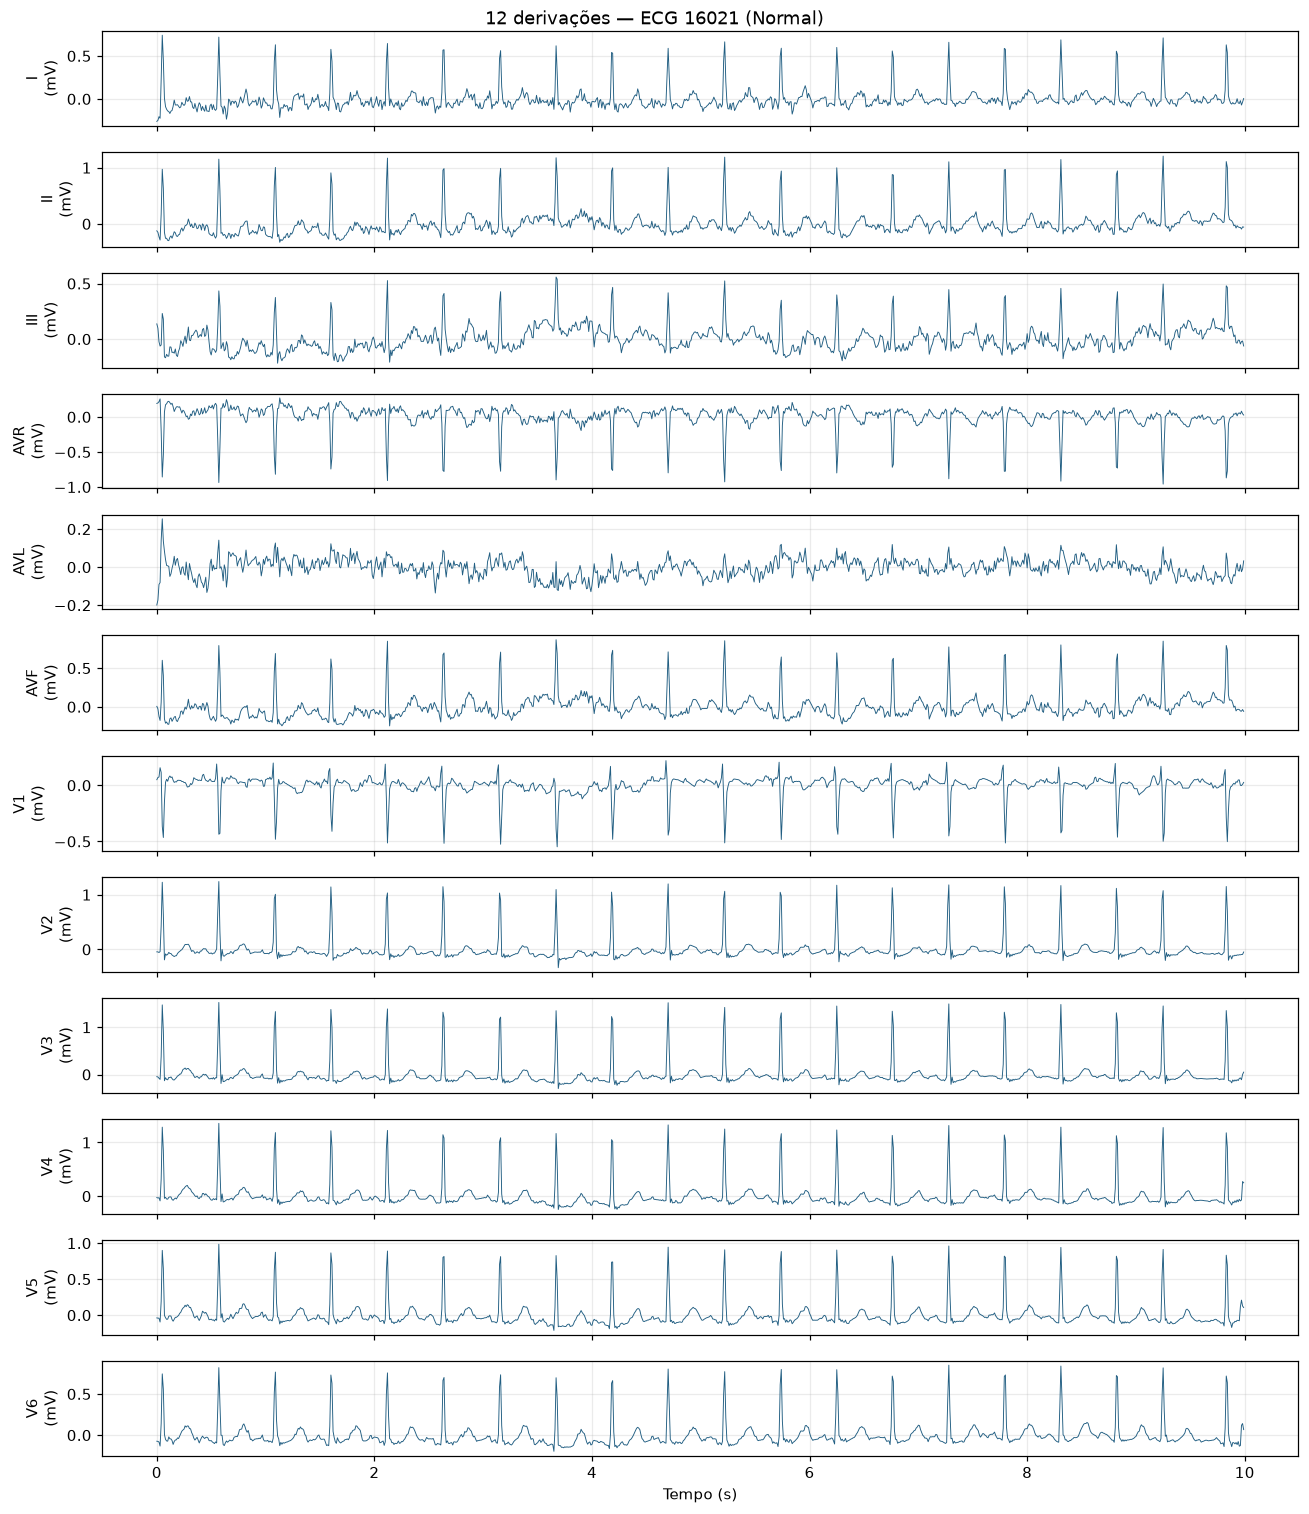

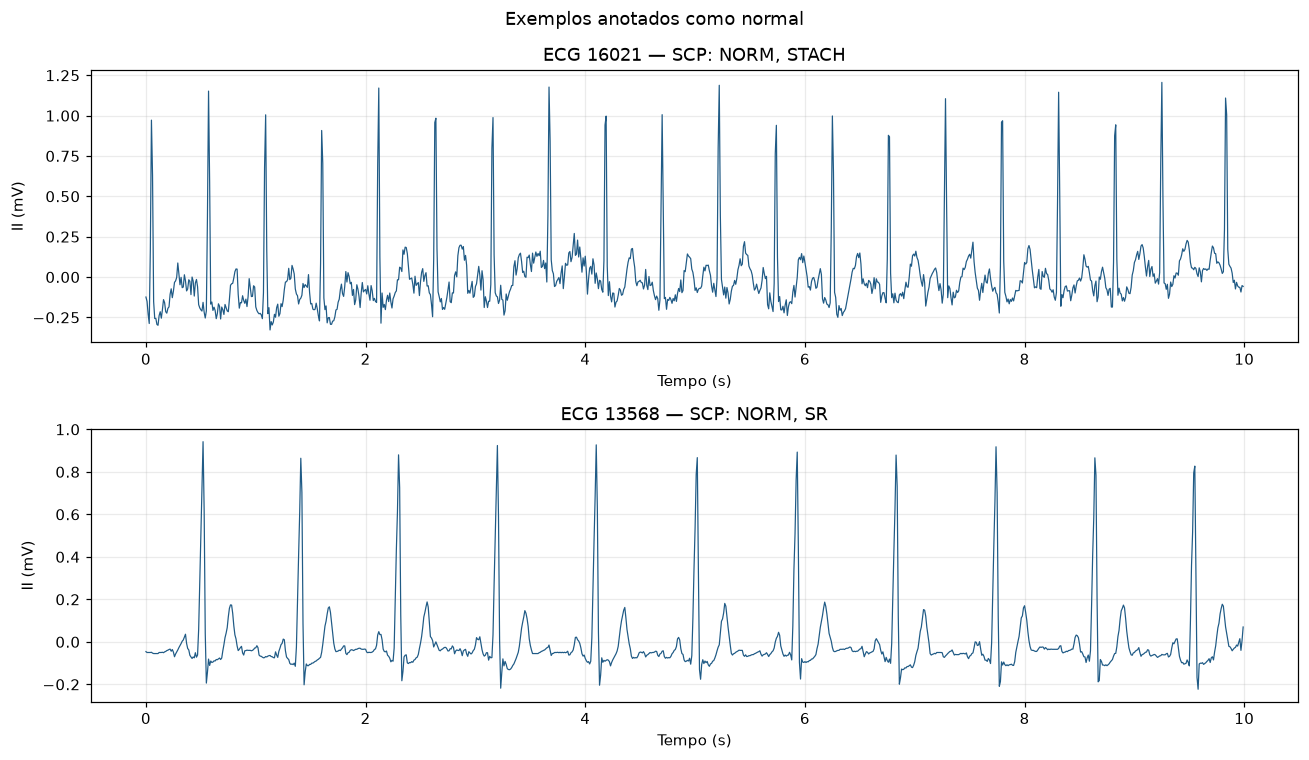

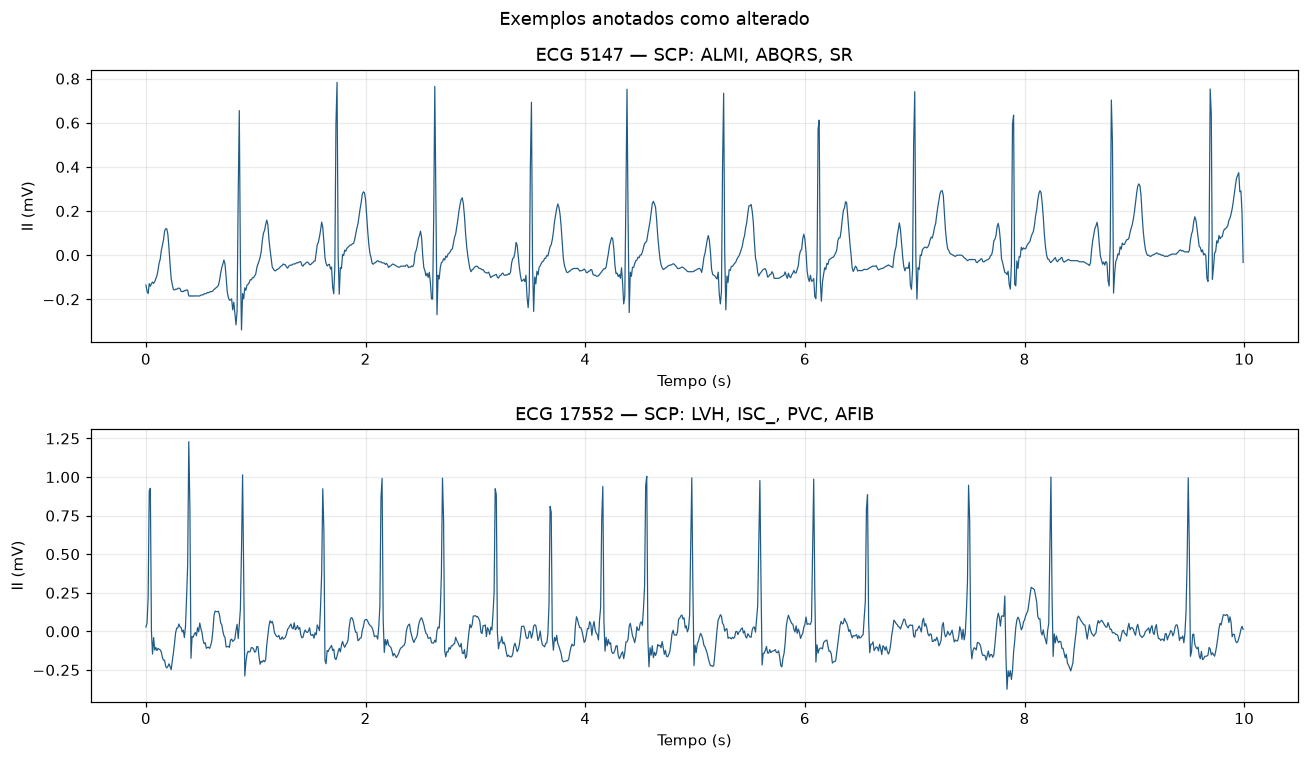

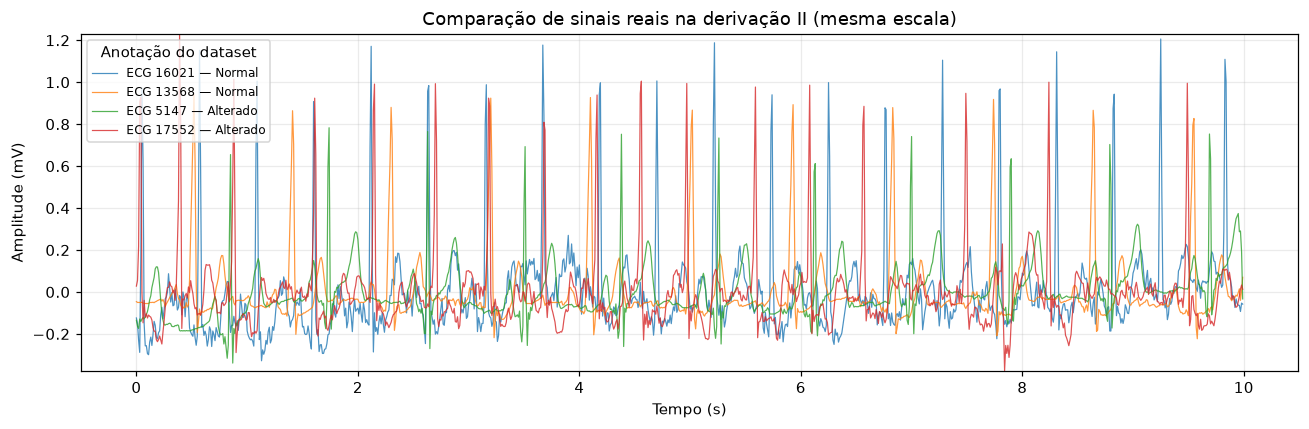

In [8]:
def desenhar_12(registro, titulo, destino):
    sinal = registro.p_signal
    tempo = np.arange(len(sinal)) / registro.fs
    fig, axes = plt.subplots(registro.n_sig, 1, figsize=(12, 14), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(tempo, sinal[:, i], lw=0.6, color='#215e82')
        ax.set_ylabel(f'{registro.sig_name[i]}\n({registro.units[i]})')
    axes[-1].set_xlabel('Tempo (s)')
    fig.suptitle(titulo)
    fig.tight_layout(); fig.savefig(pasta_figuras / destino); plt.show()

primeira = amostra.iloc[0]
desenhar_12(sinais[int(primeira.ecg_id)],
            f'12 derivações — ECG {int(primeira.ecg_id)} ({primeira.grupo_binario})',
            'ecg_12_derivacoes.png')

for grupo, nome_arquivo in [('Normal', 'exemplos_normais.png'), ('Alterado', 'exemplos_alterados.png')]:
    linhas = amostra.loc[amostra.grupo_binario.eq(grupo)]
    fig, axes = plt.subplots(len(linhas), 1, figsize=(12, 3.5 * len(linhas)), squeeze=False)
    for ax, (_, linha) in zip(axes[:, 0], linhas.iterrows()):
        reg = sinais[int(linha.ecg_id)]
        derivacao = reg.sig_name.index('II') if 'II' in reg.sig_name else 0
        t = np.arange(reg.sig_len) / reg.fs
        ax.plot(t, reg.p_signal[:, derivacao], color='#205b86', lw=0.8)
        ax.set(title=f"ECG {int(linha.ecg_id)} — SCP: {', '.join(linha.codigos_scp.keys())}",
               xlabel='Tempo (s)', ylabel=f'{reg.sig_name[derivacao]} ({reg.units[derivacao]})')
    fig.suptitle(f'Exemplos anotados como {grupo.lower()}')
    fig.tight_layout(); fig.savefig(pasta_figuras / nome_arquivo); plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
valores = []
for _, linha in amostra.iterrows():
    reg = sinais[int(linha.ecg_id)]
    derivacao = reg.sig_name.index('II') if 'II' in reg.sig_name else 0
    t = np.arange(reg.sig_len) / reg.fs
    y = reg.p_signal[:, derivacao]
    valores.append(y)
    ax.plot(t, y, lw=0.8, alpha=0.8, label=f'ECG {int(linha.ecg_id)} — {linha.grupo_binario}')
ax.set_ylim(min(float(np.min(y)) for y in valores), max(float(np.max(y)) for y in valores))
ax.set(title='Comparação de sinais reais na derivação II (mesma escala)', xlabel='Tempo (s)', ylabel='Amplitude (mV)')
ax.legend(title='Anotação do dataset', fontsize=8)
fig.tight_layout(); fig.savefig(pasta_figuras / 'comparacao_derivacao_ii.png'); plt.show()

## 5. Divisões oficiais e relação entre as tarefas

A convenção informada pelo projeto é folds **1–8 para treino**, **9 para validação** e **10 para teste**. A tabela verifica exames, pacientes e sobreposição de pacientes. Se houver sobreposição, ela é registrada para decisão futura; nenhuma partição é alterada aqui. A tabela final distingue elegibilidade pelo alvo de elegibilidade com arquivo de sinal disponível.

In [9]:
def particao(fold):
    if pd.isna(fold): return 'Fold ausente'
    if fold in range(1, 9): return 'Treino'
    if fold == 9: return 'Validação'
    if fold == 10: return 'Teste'
    return 'Fold fora de 1–10'

df['particao'] = df.strat_fold.map(particao)
particoes = df.groupby('particao', dropna=False).agg(exames=('ecg_id', 'size'), pacientes=('patient_id', 'nunique'))
display(particoes)
por_paciente = df.dropna(subset=['patient_id']).groupby('patient_id').particao.nunique()
pacientes_cruzados = por_paciente[por_paciente > 1]
print('Pacientes em mais de uma partição:', len(pacientes_cruzados))
if len(pacientes_cruzados):
    display(df[df.patient_id.isin(pacientes_cruzados.index)].groupby(['patient_id', 'particao']).size().head(20).to_frame('ECGs'))
print('Folds fora da convenção ou ausentes:', int(df.particao.isin(['Fold ausente', 'Fold fora de 1–10']).sum()))

classificacao_alvo = df.grupo_binario.isin(['Normal', 'Alterado'])
regressao_alvo = df.idade_valida
com_sinal = df.sinal_disponivel
resumo_elegibilidade = pd.DataFrame({
    'conjunto': ['Total de ECGs', 'Elegíveis para classificação', 'Elegíveis para regressão', 'Elegíveis para ambas'],
    'alvo adequado': [len(df), int(classificacao_alvo.sum()), int(regressao_alvo.sum()),
                      int((classificacao_alvo & regressao_alvo).sum())],
    'alvo adequado e sinal disponível': [int(com_sinal.sum()),
                                         int((classificacao_alvo & com_sinal).sum()),
                                         int((regressao_alvo & com_sinal).sum()),
                                         int((classificacao_alvo & regressao_alvo & com_sinal).sum())]})
display(resumo_elegibilidade)
print('Essas contagens não determinam ainda se as duas tarefas usarão o mesmo subconjunto.')

,exames,pacientes
particao,,
Teste,2198,1904
Treino,17418,15023
Validação,2183,1942


Pacientes em mais de uma partição: 0
Folds fora da convenção ou ausentes: 0


,conjunto,alvo adequado,alvo adequado e sinal disponível
0,Total de ECGs,21799,21799
1,Elegíveis para classificação,20943,20943
2,Elegíveis para regressão,21506,21506
3,Elegíveis para ambas,20659,20659


Essas contagens não determinam ainda se as duas tarefas usarão o mesmo subconjunto.


## Conclusões da Análise Exploratória

1. **Classificação binária viável:** 20.943 dos 21.799 ECGs têm diagnóstico suficiente pela regra proposta: 9.069 Normal e 11.874 Alterado (aproximadamente 43,3% e 56,7% dos elegíveis). Foram excluídos provisoriamente 445 com `NORM` e alteração simultâneos e 411 sem superclasse diagnóstica reconhecida. MI, STTC, CD e HYP podem se sobrepor; há 5.144 ECGs com múltiplas superclasses.
2. **Regressão da idade viável:** 21.506 ECGs têm idade válida; 293 exibem `300`, valor de anonimização, e não devem ser tratados como idade cronológica. As idades válidas vão de 2 a 89 anos, com média de 59,54, mediana de 61 e desvio padrão de 16,76 anos.
3. **Desbalanceamento:** a divisão binária é moderadamente desigual. As superclasses individuais têm frequências distintas e sobreposição. Convém avaliar desempenho por grupo e faixa etária no futuro, sem definir ponderação nesta etapa.
4. **Ausências e qualidade:** não faltam `patient_id`, `age`, `scp_codes`, `strat_fold` ou `filename_lr`; todos os 21.799 pares `.hea`/`.dat` de 100 Hz foram encontrados. Não há `ecg_id` ou caminho de sinal repetido. Dois registros têm metadados iguais após retirar IDs e caminhos e são apenas candidatos a inspeção. Os quatro ECGs lidos com WFDB têm 12 derivações, 1.000 amostras, 100 Hz, 10 segundos, unidade mV e nenhum NaN, infinito ou derivação constante; isso não certifica todos os sinais.
5. **Vazamento:** os folds oficiais resultam em 17.418 exames de treino, 2.183 de validação e 2.198 de teste, sem pacientes atravessando essas três partições. Preservar essa separação e ajustar futuras transformações apenas no treino.
6. **Dificuldades futuras:** idade média dos grupos claramente definidos difere (51,99 anos em Normal; 65,40 em Alterado), o que pode atuar como fator de confusão. Anotações diagnósticas sobrepostas e artefatos de aquisição também exigem cuidado.
7. **Recomendações para o pré-processamento futuro:** manter as 12 derivações e suas unidades, inspecionar a qualidade dos sinais em lotes, documentar restrições adicionais e decidir entre subconjuntos distintos por tarefa ou a interseção de 20.659 exames elegíveis para ambas. Nenhuma dessas decisões altera os dados nesta EDA.